<a href="https://colab.research.google.com/github/rSith/machine-learning-specialization/blob/rSith-dev/ML_Specialization_04_The_Problem_of_Overfitting.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# The Problem of Overfitting & Regularization

In [14]:
import copy, math
import numpy as np
import matplotlib.pyplot as plt
np.set_printoptions(precision=4, suppress=True)

In [15]:
def sigmoid(z):
    return 1 / (1 + np.exp(-z))

def zscore_normalize_features(X):
    """Week 2 feature scaling. Returns X_norm, mu, sigma (per column)."""
    mu = np.mean(X, axis=0)
    sigma = np.std(X, axis=0)
    return (X - mu) / sigma, mu, sigma

def map_one_feature(x, degree):
    """x -> [x, x^2, ..., x^degree]   shape (m, degree)"""
    x = np.atleast_1d(x)
    return np.stack([x ** i for i in range(1, degree + 1)], axis=1)

def map_feature(x0, x1, degree):
    """Two features -> all polynomial terms x0^(i-j) * x1^j up to `degree` (same as the lab)."""
    x0, x1 = np.atleast_1d(x0), np.atleast_1d(x1)
    out = [x0 ** (i - j) * x1 ** j for i in range(1, degree + 1) for j in range(i + 1)]
    return np.stack(out, axis=1)

def plot_data(X, y, ax, s=40):
    pos, neg = y == 1, y == 0
    ax.scatter(X[pos, 0], X[pos, 1], marker='x', s=s, c='red', label="y=1")
    ax.scatter(X[neg, 0], X[neg, 1], marker='o', s=s, facecolors='none',
               edgecolors='#0096ff', lw=1.5, label="y=0")

## 1. The problem of overfitting

Linear and logistic regression work well for many tasks, but they can run into a problem called **overfitting**, which makes them perform poorly on new data. The almost opposite problem is **underfitting**.

> - **Underfitting (high bias):** the model does not fit even the training set well. There is a clear pattern in the data that the model cannot capture.
> - **Overfitting (high variance):** the model fits the training set *too* well, including its noise, and does not **generalize** to new examples.
> - **Generalization:** making good predictions on brand new examples the model has never seen.

> **Note on "bias".** In machine learning, *bias* also means unfair treatment of groups (e.g. by gender or ethnicity), which is important to check. Here it has its **technical** meaning: a strong preconception, e.g. "price is a straight line in size", that the model cannot get away from.

### 1.1 Regression example: housing prices

Five houses, size $x$ (1000 sqft) and price $y$ ($1000s). The price grows with size but flattens out. We fit three models:

| model | features | $f_{\mathbf{w},b}(x)$ |
|---|---|---|
| linear | $x$ | $w_1x + b$ |
| quadratic | $x, x^2$ | $w_1x + w_2x^2 + b$ |
| 4th-order polynomial | $x, x^2, x^3, x^4$ | $w_1x + w_2x^2 + w_3x^3 + w_4x^4 + b$ |

degree 1: training cost J =  351.747
degree 2: training cost J =  252.889
degree 4: training cost J =    0.000


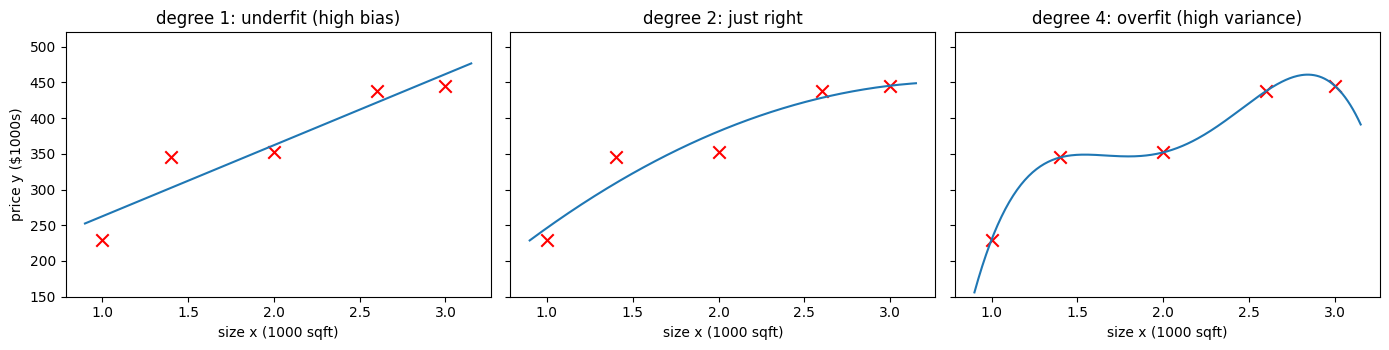

In [16]:
x_house = np.array([1.0, 1.4, 2.0, 2.6, 3.0])        # size (1000 sqft)
y_house = np.array([230., 345., 352., 438., 445.])   # price ($1000s)

def fit_poly_exact(x, y, degree):
    """Least-squares fit of a polynomial (minimises the squared error cost directly)."""
    return np.polyfit(x, y, degree)                  # coefficients, highest power first

def mse_cost(y_hat, y):
    return np.mean((y_hat - y) ** 2) / 2             # J = 1/(2m) * sum(err^2)

xs = np.linspace(0.9, 3.15, 300)
titles = ["degree 1: underfit (high bias)", "degree 2: just right", "degree 4: overfit (high variance)"]
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, d, t in zip(ax, [1, 2, 4], titles):
    c = fit_poly_exact(x_house, y_house, d)
    a.plot(xs, np.polyval(c, xs), c='tab:blue')
    a.scatter(x_house, y_house, marker='x', s=80, c='red')
    a.set_title(t); a.set_xlabel("size x (1000 sqft)")
    print(f"degree {d}: training cost J = {mse_cost(np.polyval(c, x_house), y_house):8.3f}")
ax[0].set_ylabel("price y ($1000s)"); ax[0].set_ylim(150, 520)
plt.tight_layout(); plt.show()

**Observation.**
- **Degree 1** is a straight line. It misses the flattening pattern even on the training set → **underfit / high bias**.
- **Degree 2** does not pass through every point, but it follows the trend. A new house would probably get a sensible price → **just right**, it should **generalize**.
- **Degree 4** passes through all 5 points exactly, so the training cost is **0**. But the curve is wiggly: near $x = 3.1$ it predicts a *bigger* house is *cheaper*. It fits the data "too well" → **overfit / high variance**.

A training cost of 0 does **not** mean a good model.

### 1.2 Training error vs. error on new data

"Generalize well" can be measured. The course lab builds its regression data as $y = x^2$ plus noise. We use the same generator to make a **training set** and a separate **new data** set, then fit polynomials of increasing degree (features scaled with z-score, as in Week 2).

In [17]:
def make_quadratic_data(m, seed):
    """Same generator as plt_overfit.linear_data: y = x^2 with up to +/-35% noise."""
    rng = np.random.default_rng(seed)
    x = np.sort(rng.uniform(0, 29, m))
    y_ideal = x ** 2
    return x, y_ideal + 0.7 * y_ideal * (rng.random(m) - 0.5)

x_tr, y_tr = make_quadratic_data(12, seed=1)          # small training set
x_te, y_te = make_quadratic_data(200, seed=2)         # "new houses" the model never saw
xs_q = np.linspace(0, 29, 300)                        # for plotting curves

def fit_normal_eq(X, y, lambda_=0.0):
    """Exact minimiser of the (regularized) squared error cost (b is not regularized).
    Used for speed and accuracy instead of gradient descent; see Part 4.4."""
    m, n = X.shape
    X_mu, y_mu = X.mean(axis=0), y.mean()
    Xc, yc = X - X_mu, y - y_mu                        # centering removes b from the system
    w = np.linalg.solve(Xc.T @ Xc + lambda_ * np.eye(n), Xc.T @ yc)
    b = y_mu - X_mu @ w
    return w, b

print("degree | train cost | cost on new data")
for d in [1, 2, 4, 6, 9]:
    Xtr = map_one_feature(x_tr, d)
    Xtr_n, mu, sig = zscore_normalize_features(Xtr)
    w, b = fit_normal_eq(Xtr_n, y_tr)
    Xte_n = (map_one_feature(x_te, d) - mu) / sig
    print(f"{d:6d} | {mse_cost(Xtr_n @ w + b, y_tr):10.1f} | {mse_cost(Xte_n @ w + b, y_te):12.1f}")

degree | train cost | cost on new data
     1 |     7989.2 |       6085.1
     2 |     2541.8 |       3676.1
     4 |     2334.0 |       3942.4
     6 |     1591.9 |       8926.4
     9 |       25.6 |    1405897.1


**Observation.**
- The **training** cost always goes down as the degree goes up. More features = more freedom to fit the training points.
- The cost on **new data** is high for degree 1 (underfit), lowest around degree 2, and then **explodes** for high degrees (overfit).
- So we cannot pick a model by training cost alone. (Course 2 covers proper tools for this: train / cross-validation / test sets.)

### 1.3 Why "high variance"?

An overfit model tries very hard to fit every single example. If the training set were just a little different, the fitted function could be totally different. Two engineers with slightly different data sets would get **highly variable** predictions.

Below, 5 "engineers" each get their own 12 examples from the same generator and fit a degree-2 and a degree-9 model.

degree 2: predictions at x = 26 -> [738 686 861 726 704]
degree 9: predictions at x = 26 -> [888 690 872 774 483]


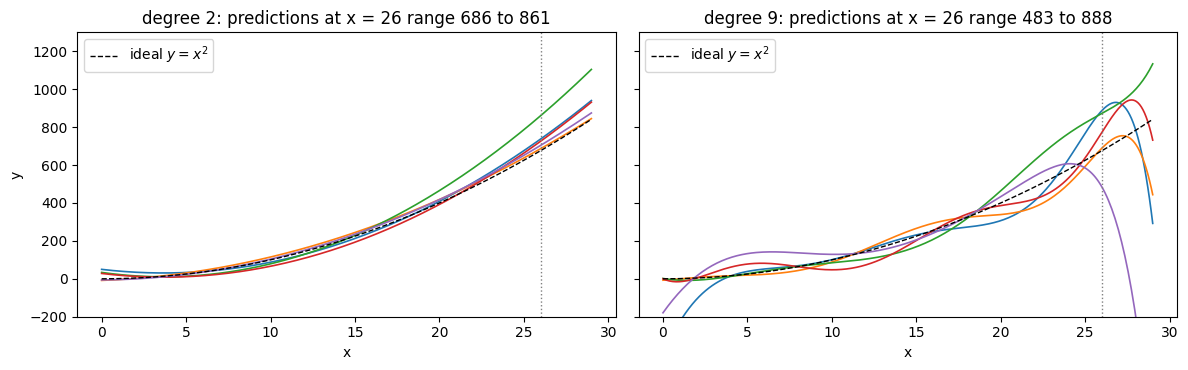

In [18]:
fig, ax = plt.subplots(1, 2, figsize=(12, 3.8), sharey=True)
x_new = 26.0                                           # a new example none of them trained on
for a, d in zip(ax, [2, 9]):
    preds = []
    for seed in range(10, 15):
        x_s, y_s = make_quadratic_data(12, seed)
        Xs_n, mu, sig = zscore_normalize_features(map_one_feature(x_s, d))
        # Use a tiny lambda_ (e.g., 1e-7) to prevent the singular matrix LinAlgError on degree 9
        w, b = fit_normal_eq(Xs_n, y_s, lambda_=1e-7 if d == 9 else 0.0)
        a.plot(xs_q, ((map_one_feature(xs_q, d) - mu) / sig) @ w + b, lw=1.2)
        preds.append((((map_one_feature(x_new, d) - mu) / sig) @ w + b)[0])
    a.plot(xs_q, xs_q ** 2, 'k--', lw=1, label="ideal $y = x^2$")
    a.axvline(x_new, c='gray', ls=':', lw=1)
    a.set_title(f"degree {d}: predictions at x = {x_new:g} range {min(preds):.0f} to {max(preds):.0f}")
    a.set_xlabel("x"); a.set_ylim(-200, 1300); a.legend(loc="upper left")
    print(f"degree {d}: predictions at x = {x_new:g} ->", np.round(preds).astype(int))
ax[0].set_ylabel("y")
plt.tight_layout(); plt.show()

**Observation.** The five quadratic models are almost the same line, and they predict similar values for the new example. The five degree-9 models swing in completely different ways, so their predictions are all over the place. That sensitivity to the exact training data is what **high variance** means.

> **Goldilocks:** one porridge is too cold (underfit), one is too hot (overfit), one is *just right*. The goal of machine learning is a model with **neither high bias nor high variance**.

### 1.4 Classification example: tumors

Overfitting happens in classification too. We use the same data generator as the course lab: two features $x_0, x_1$ (think tumor size and patient age, scaled to $[-1, 1]$), and the label is roughly "above a parabola" with some noise.

$$f_{\mathbf{w},b}(\mathbf{x}) = g(z), \qquad z = \mathbf{w}\cdot\text{features}(\mathbf{x}) + b$$

- degree 1: $z = w_1x_0 + w_2x_1 + b$ → straight-line boundary
- degree 2: adds $x_0^2,\ x_0x_1,\ x_1^2$ → ellipse / parabola-shaped boundary
- degree 6: 27 polynomial features → very flexible boundary

In [19]:
# same data as plt_overfit.logistic_data
m_c = 50
np.random.seed(2)
X_cls = 2 * (np.random.rand(m_c, 2) - [0.5, 0.5])
y_cls = (X_cls[:, 1] + 0.5 > X_cls[:, 0] ** 2 + 0.5 * np.random.rand(m_c)).astype(int)
print(f"X_cls shape: {X_cls.shape}, positives: {y_cls.sum()}, negatives: {(y_cls == 0).sum()}")

X_cls shape: (50, 2), positives: 21, negatives: 29


We need logistic regression with gradient descent from the last notebook. Below it already has a `lambda_` argument, which we will explain in Part 3. For now we use `lambda_ = 0` (plain logistic regression).

In [20]:
def compute_cost_logistic_reg(X, y, w, b, lambda_=0.0):
    m = X.shape[0]
    f = sigmoid(X @ w + b)
    f = np.clip(f, 1e-15, 1 - 1e-15)                       # avoid log(0) for very confident models
    cost = np.mean(-y * np.log(f) - (1 - y) * np.log(1 - f))
    return cost + (lambda_ / (2 * m)) * np.sum(w ** 2)

def compute_gradient_logistic_reg(X, y, w, b, lambda_=0.0):
    m = X.shape[0]
    err = sigmoid(X @ w + b) - y                           # (m,)
    dj_dw = (X.T @ err) / m + (lambda_ / m) * w            # (n,)  <- regularization term
    dj_db = np.sum(err) / m                                # b is not regularized
    return dj_db, dj_dw

def gradient_descent_logistic(X, y, w_in, b_in, alpha, num_iters, lambda_=0.0):
    w, b = copy.deepcopy(w_in), b_in
    for _ in range(num_iters):
        dj_db, dj_dw = compute_gradient_logistic_reg(X, y, w, b, lambda_)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
    return w, b

def train_logistic_poly(X, y, degree, lambda_=0.0, alpha=1.0, num_iters=300000):
    Xm = map_feature(X[:, 0], X[:, 1], degree)
    Xm_n, mu, sig = zscore_normalize_features(Xm)
    w, b = gradient_descent_logistic(Xm_n, y, np.zeros(Xm.shape[1]), 0., alpha, num_iters, lambda_)
    return w, b, mu, sig

def plot_boundary(ax, w, b, mu, sig, degree):
    g0, g1 = np.meshgrid(np.linspace(-1, 1, 250), np.linspace(-1, 1, 250))
    Xg = (map_feature(g0.ravel(), g1.ravel(), degree) - mu) / sig
    z = (Xg @ w + b).reshape(g0.shape)
    ax.contour(g0, g1, z, levels=[0], colors='g', linewidths=2)     # decision boundary z = 0

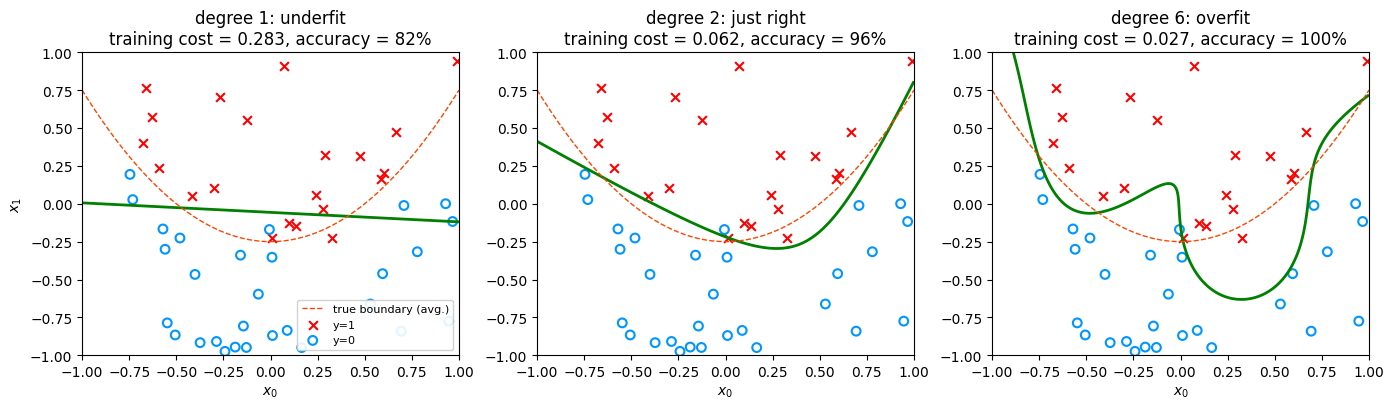

In [21]:
xi = np.linspace(-1, 1, 100)
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, d, t in zip(ax, [1, 2, 6], ["degree 1: underfit", "degree 2: just right", "degree 6: overfit"]):
    w, b, mu, sig = train_logistic_poly(X_cls, y_cls, d)
    Xn = (map_feature(X_cls[:, 0], X_cls[:, 1], d) - mu) / sig
    acc = np.mean((sigmoid(Xn @ w + b) >= 0.5) == y_cls)
    plot_boundary(a, w, b, mu, sig, d)
    a.plot(xi, xi ** 2 - 0.25, '--', c='orangered', lw=1, label="true boundary (avg.)")
    plot_data(X_cls, y_cls, a)
    a.set_title(f"{t}\ntraining cost = {compute_cost_logistic_reg(Xn, y_cls, w, b):.3f}, accuracy = {acc:.0%}")
    a.set_xlim(-1, 1); a.set_ylim(-1, 1); a.set_xlabel("$x_0$")
ax[0].set_ylabel("$x_1$"); ax[0].legend(loc='lower right', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

**Observation.**
- **Degree 1:** a straight line. "Kind of okay", but it clearly misses the curved pattern → **underfit**.
- **Degree 2:** a parabola-like boundary close to the ideal curve. A few points are still misclassified, which is fine. It should generalize to new patients → **just right**.
- **Degree 6:** the model twists the boundary until it classifies **every** training point correctly (lowest training cost, 100% accuracy). But the wavy shape does not look like a sensible medical rule → **overfit**.

The dashed line is the boundary the data was generated from, $x_1 = x_0^2 - 0.25$ on average (the label is $x_1 + 0.5 > x_0^2 + 0.5\cdot\text{noise}$).

## 2. Addressing overfitting

Three main options:

| # | option | idea | downside |
|---|---|---|---|
| 1 | **Collect more training data** | with more examples, even a complex model learns a less wiggly function | more data is not always available |
| 2 | **Use fewer features (feature selection)** | keep only the most relevant features, e.g. size, bedrooms, age instead of 100 features | throws away information that might be useful |
| 3 | **Regularization** | keep all features, but shrink the parameters $w_j$ so no feature has an overly large effect | need to choose $\lambda$ |

- Setting a parameter $w_j = 0$ is the same as removing feature $j$. Regularization is a **gentler** version: it makes $w_j$ small without forcing it to exactly 0.
- By convention we regularize only $w_1 \dots w_n$, **not** $b$. It makes very little difference in practice.
- Course 2 covers algorithms for choosing features automatically, and tools for *diagnosing* over/underfitting.

### 2.1 Option 1: more data (Lab 08 "add data")

Same degree-6 model, trained on 12 examples vs. 80 examples from the same generator.

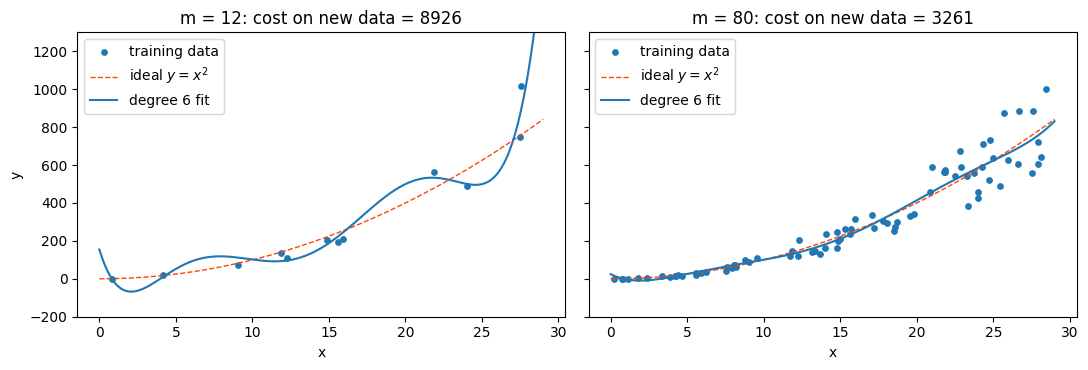

In [22]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.8), sharey=True)
for a, m_ in zip(ax, [12, 80]):
    x_, y_ = make_quadratic_data(m_, seed=1)
    X_n, mu, sig = zscore_normalize_features(map_one_feature(x_, 6))
    w, b = fit_normal_eq(X_n, y_)
    Xq = (map_one_feature(xs_q, 6) - mu) / sig
    Xte_n = (map_one_feature(x_te, 6) - mu) / sig
    a.scatter(x_, y_, s=15, label="training data")
    a.plot(xs_q, xs_q ** 2, '--', c='orangered', lw=1, label="ideal $y = x^2$")
    a.plot(xs_q, Xq @ w + b, c='tab:blue', label="degree 6 fit")
    a.set_title(f"m = {m_}: cost on new data = {mse_cost(Xte_n @ w + b, y_te):.0f}")
    a.set_xlabel("x"); a.set_ylim(-200, 1300); a.legend(loc='upper left')
ax[0].set_ylabel("y")
plt.tight_layout(); plt.show()

**Observation.** With few examples the degree-6 curve swings around between the points. With many examples the *same* model is forced to follow the real trend, and the cost on new data drops a lot. **More data is the number one tool against overfitting**, when you can get it.

### 2.2 Option 2: fewer features

Using fewer polynomial features is exactly the "degree 2 vs degree 6" choice from Part 1. With 100 house features, we would instead pick the most relevant subset by intuition.

### 2.3 Option 3: regularization — why small weights help

Look at the size of the parameters of the overfit house model from 1.1.

In [23]:
for d in [2, 4]:
    c = fit_poly_exact(x_house, y_house, d)[::-1]          # reverse -> [b, w1, w2, ...]
    print(f"degree {d}:  b = {c[0]:9.1f},  w = {c[1:]}")

degree 2:  b =      39.8,  w = [242.0055 -35.6117]
degree 4:  b =   -2531.4,  w = [ 6115.8472 -4759.9861  1599.6528  -194.0972]


**Observation.** The overfit model needs **huge** weights with alternating signs (e.g. $+$ thousands, $-$ thousands) that cancel each other to pass through every point. That is what makes the curve wiggly. If we keep the weights **small**, the curve has to be smoother. Regularization does exactly that.

## 3. Cost function with regularization

### 3.1 Intuition: penalize $w_3$ and $w_4$

The quadratic model fits well; the 4th-order one overfits. Suppose we modify the cost and add a big penalty on $w_3$ and $w_4$:

$$\min_{\mathbf{w},b} \; \frac{1}{2m}\sum_{i=1}^{m}\left(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\right)^2 + 1000\,w_3^2 + 1000\,w_4^2$$

The only way to make this small is to make $w_3$ and $w_4$ close to 0. That nearly cancels the $x^3$ and $x^4$ features, so the model behaves almost like a quadratic.

no penalty:            w = [ 6115.8472 -4759.9861  1599.6528  -194.0972]
1000*w3^2 + 1000*w4^2: w = [242.4533 -35.7951   0.001    0.0071]


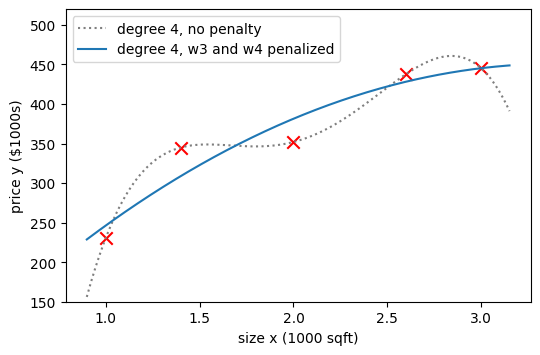

In [24]:
def fit_with_penalty(X, y, penalty):
    """Minimise 1/(2m)*sum(err^2) + sum_j penalty[j]*w_j^2  (b not penalized), exactly."""
    m, n = X.shape
    X_mu, y_mu = X.mean(axis=0), y.mean()
    Xc, yc = X - X_mu, y - y_mu
    w = np.linalg.solve(Xc.T @ Xc / m + 2 * np.diag(penalty), Xc.T @ yc / m)
    return w, y_mu - X_mu @ w

X4_house = map_one_feature(x_house, 4)                      # [x, x^2, x^3, x^4] raw features
w_free, b_free = fit_with_penalty(X4_house, y_house, np.zeros(4))
w_pen,  b_pen  = fit_with_penalty(X4_house, y_house, np.array([0, 0, 1000, 1000]))
print("no penalty:            w =", w_free)
print("1000*w3^2 + 1000*w4^2: w =", w_pen)

X4_xs = map_one_feature(xs, 4)
fig, ax = plt.subplots(1, 1, figsize=(6, 3.8))
ax.plot(xs, X4_xs @ w_free + b_free, c='tab:gray', ls=':', label="degree 4, no penalty")
ax.plot(xs, X4_xs @ w_pen + b_pen, c='tab:blue', label="degree 4, w3 and w4 penalized")
ax.scatter(x_house, y_house, marker='x', s=80, c='red')
ax.set_xlabel("size x (1000 sqft)"); ax.set_ylabel("price y ($1000s)"); ax.set_ylim(150, 520)
ax.legend(); plt.show()

**Observation.** With the penalty, $w_3$ and $w_4$ shrink to almost 0 and the curve is close to the quadratic fit, with only tiny contributions from $x^3$ and $x^4$.

### 3.2 The general regularized cost

In real problems (e.g. 100 features) we don't know *which* weights to penalize, so we penalize **all** of them a little:

$$J(\mathbf{w},b) = \underbrace{\frac{1}{2m}\sum_{i=0}^{m-1}\left(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\right)^2}_{\text{fit the data}} + \underbrace{\frac{\lambda}{2m}\sum_{j=0}^{n-1} w_j^2}_{\text{keep } w_j \text{ small}} \tag{1}$$

- $\lambda$ (lambda) is the **regularization parameter**. Like the learning rate $\alpha$, we have to choose it.
- Both terms are divided by $2m$. Then the same $\lambda$ is more likely to keep working when the training set grows.
- $b$ is **not** regularized (common convention; including $\frac{\lambda}{2m}b^2$ makes very little difference).
- $\lambda$ sets the **trade-off** between the two goals.

### 3.3 Implementation (Lab 09)
The lab uses a `for` loop over examples and features. The vectorized version gives the same answer.

In [25]:
def compute_cost_linear_reg_loop(X, y, w, b, lambda_=1):
    """Lab 09 version: loops over all m examples and n features."""
    m, n = X.shape
    cost = 0.
    for i in range(m):
        f_wb_i = np.dot(X[i], w) + b
        cost = cost + (f_wb_i - y[i]) ** 2
    cost = cost / (2 * m)

    reg_cost = 0
    for j in range(n):
        reg_cost += w[j] ** 2
    reg_cost = (lambda_ / (2 * m)) * reg_cost
    return cost + reg_cost

def compute_cost_linear_reg(X, y, w, b, lambda_=1):
    m = X.shape[0]
    err = X @ w + b - y                                         # (m,)
    return np.sum(err ** 2) / (2 * m) + (lambda_ / (2 * m)) * np.sum(w ** 2)

In [26]:
np.random.seed(1)
X_tmp = np.random.rand(5, 6)
y_tmp = np.array([0, 1, 0, 1, 0])
w_tmp = np.random.rand(X_tmp.shape[1]).reshape(-1,) - 0.5
b_tmp = 0.5
lambda_tmp = 0.7
print("Regularized cost (loop):      ", compute_cost_linear_reg_loop(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp))
print("Regularized cost (vectorized):", compute_cost_linear_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp))
# expected: 0.07917239320214275

Regularized cost (loop):       0.07917239320214277
Regularized cost (vectorized): 0.07917239320214275


### 3.4 Choosing $\lambda$: too small, too large, just right

Degree-4 model on the house data, with features scaled, for three values of $\lambda$.

lambda = 0     : w = [  4510.826  -14168.3799  15608.8218  -5866.4038],  b = 362.0
lambda = 0.05  : w = [ 89.0699  20.8156 -12.5799 -26.468 ],  b = 362.0
lambda = 1e+10 : w = [0. 0. 0. 0.],  b = 362.0


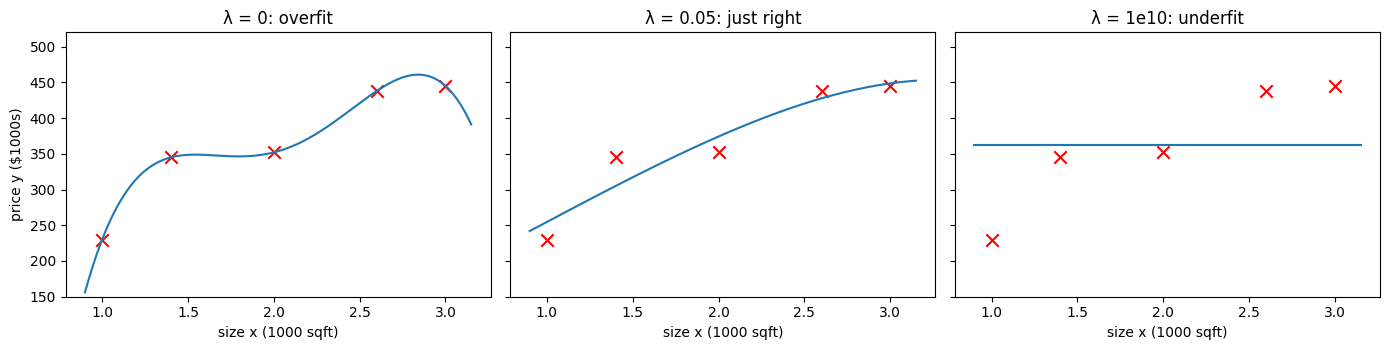

In [27]:
X4_n, mu4, sig4 = zscore_normalize_features(X4_house)
X4_xs_n = (X4_xs - mu4) / sig4
fig, ax = plt.subplots(1, 3, figsize=(14, 3.6), sharey=True)
for a, lam, t in zip(ax, [0, 0.05, 1e10], ["λ = 0: overfit", "λ = 0.05: just right", "λ = 1e10: underfit"]):
    w, b = fit_normal_eq(X4_n, y_house, lam)
    a.plot(xs, X4_xs_n @ w + b, c='tab:blue')
    a.scatter(x_house, y_house, marker='x', s=80, c='red')
    a.set_title(t); a.set_xlabel("size x (1000 sqft)")
    print(f"lambda = {lam:<6g}: w = {w},  b = {b:.1f}")
ax[0].set_ylabel("price y ($1000s)"); ax[0].set_ylim(150, 520)
plt.tight_layout(); plt.show()

**Observation.**
- **$\lambda = 0$:** the regularization term disappears → the wiggly overfit curve.
- **$\lambda = 10^{10}$:** the only way to minimize $J$ is $w_j \approx 0$, so $f(x) \approx b$, a **horizontal line** → underfit.
- **$\lambda$ in between:** we keep all four polynomial features, but the curve is smooth. Model selection (Course 2) gives proper ways to pick $\lambda$.

## 4. Regularized linear regression

### 4.1 Gradient descent
The update rule does not change; only the derivative for $w_j$ gets one extra term:

$$\begin{align*}
w_j &:= w_j - \alpha \left[\frac{1}{m} \sum_{i=0}^{m-1} \left(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\right)x_{j}^{(i)} + \frac{\lambda}{m} w_j\right] \tag{2}\\
b &:= b - \alpha \frac{1}{m} \sum_{i=0}^{m-1} \left(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\right) \tag{3}
\end{align*}$$

$b$ is not regularized, so its update is the same as before. Remember the **simultaneous update**.

### 4.2 (Optional) What the extra term really does
Rearranging the $w_j$ update:

$$w_j := \underbrace{w_j\left(1 - \alpha\frac{\lambda}{m}\right)}_{\text{shrink a little}} - \underbrace{\alpha\frac{1}{m}\sum_{i=0}^{m-1}\left(f_{\mathbf{w},b}(\mathbf{x}^{(i)}) - y^{(i)}\right)x_j^{(i)}}_{\text{usual update from Week 2}}$$

With $\alpha = 0.01$, $\lambda = 1$, $m = 50$:

In [28]:
alpha, lambda_, m = 0.01, 1, 50
shrink = 1 - alpha * lambda_ / m
print(f"1 - alpha*lambda/m = {shrink}")
print(f"after 1,000 iterations of shrinking only, w_j would be multiplied by {shrink ** 1000:.3f}")

1 - alpha*lambda/m = 0.9998
after 1,000 iterations of shrinking only, w_j would be multiplied by 0.819


**Observation.** Every iteration, regularization multiplies $w_j$ by a number **slightly less than 1** (0.9998) before the usual update. Over many iterations this keeps the weights small. (This is why regularization is also called **weight decay**.)

**(Optional) Where the extra term comes from:** $\frac{\partial}{\partial w_j}\frac{\lambda}{2m}\sum_{k} w_k^2 = \frac{\lambda}{2m}\cdot 2w_j = \frac{\lambda}{m}w_j$. Only the $k = j$ term depends on $w_j$, so the sum disappears and the 2s cancel.

### 4.3 Computing the gradient

In [29]:
def compute_gradient_linear_reg_loop(X, y, w, b, lambda_):
    """Lab 09 version (loops)."""
    m, n = X.shape
    dj_dw = np.zeros((n,))
    dj_db = 0.
    for i in range(m):
        err = (np.dot(X[i], w) + b) - y[i]
        for j in range(n):
            dj_dw[j] = dj_dw[j] + err * X[i, j]
        dj_db = dj_db + err
    dj_dw = dj_dw / m
    dj_db = dj_db / m
    for j in range(n):
        dj_dw[j] = dj_dw[j] + (lambda_ / m) * w[j]
    return dj_db, dj_dw

def compute_gradient_linear_reg(X, y, w, b, lambda_):
    m = X.shape[0]
    err = X @ w + b - y                                     # (m,)
    dj_dw = (X.T @ err) / m + (lambda_ / m) * w             # (n,)  <- only change from Week 2
    dj_db = np.sum(err) / m
    return dj_db, dj_dw

In [30]:
np.random.seed(1)
X_tmp = np.random.rand(5, 3)
y_tmp = np.array([0, 1, 0, 1, 0])
w_tmp = np.random.rand(X_tmp.shape[1])
b_tmp = 0.5
lambda_tmp = 0.7
for fn in [compute_gradient_linear_reg_loop, compute_gradient_linear_reg]:
    dj_db_tmp, dj_dw_tmp = fn(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp)
    print(f"{fn.__name__:34s} dj_db: {dj_db_tmp}")
    print(f"{'':34s} Regularized dj_dw: {dj_dw_tmp.tolist()}")
# expected: dj_db: 0.6648774569425726
#           dj_dw: [0.29653214748822276, 0.4911679625918033, 0.21645877535865857]

compute_gradient_linear_reg_loop   dj_db: 0.6648774569425726
                                   Regularized dj_dw: [0.29653214748822276, 0.4911679625918033, 0.21645877535865857]
compute_gradient_linear_reg        dj_db: 0.6648774569425726
                                   Regularized dj_dw: [0.29653214748822276, 0.4911679625918033, 0.2164587753586586]


### 4.4 Gradient descent loop

In [31]:
def gradient_descent_linear_reg(X, y, w_in, b_in, alpha, num_iters, lambda_=0.0):
    w, b = copy.deepcopy(w_in), b_in
    J_history = []
    for i in range(num_iters):
        dj_db, dj_dw = compute_gradient_linear_reg(X, y, w, b, lambda_)
        w = w - alpha * dj_dw
        b = b - alpha * dj_db
        if i < 100000:
            J_history.append(compute_cost_linear_reg(X, y, w, b, lambda_))
    return w, b, J_history

Train the degree-6 model on the 12-example training set from 1.2 with $\lambda = 1$, and compare it with the unregularized ($\lambda = 0$) model.

λ = 1, gradient descent: w = [58.111  58.4557 52.8058 47.3314 43.4031 41.1519]
λ = 1, exact solution:   w = [58.111  58.4557 52.8058 47.3314 43.4031 41.1519]
λ = 0, exact solution:   w = [  -2161.217    26528.4651 -114803.0891  226025.6183 -204709.8861
   69446.9948] 

λ = 0: sum(w^2) = 111704782283.3 | train cost =  1591.9 | cost on new data =  8926.4
λ = 1: sum(w^2) =        15400.0 | train cost =  2359.8 | cost on new data =  3998.6


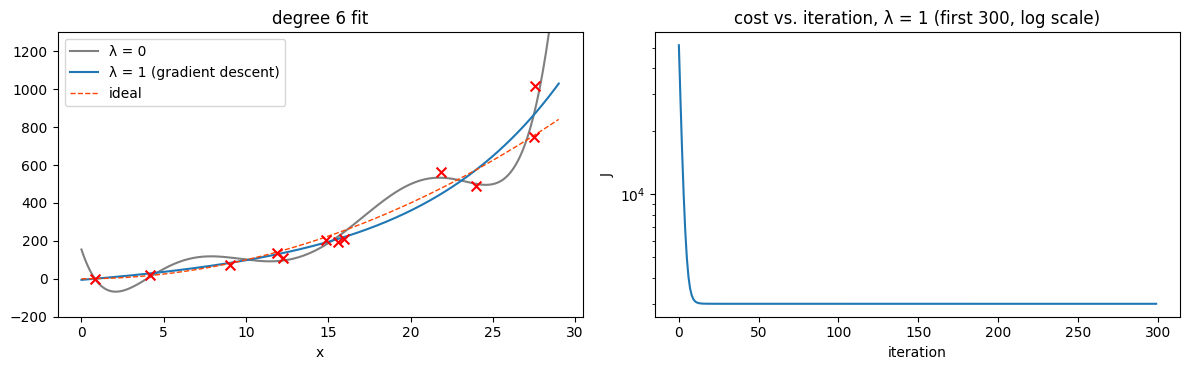

In [32]:
X6_tr = map_one_feature(x_tr, 6)
X6_n, mu6, sig6 = zscore_normalize_features(X6_tr)
X6_te_n = (map_one_feature(x_te, 6) - mu6) / sig6
X6_q = (map_one_feature(xs_q, 6) - mu6) / sig6

w_gd, b_gd, J_hist = gradient_descent_linear_reg(X6_n, y_tr, np.zeros(6), 0., alpha=0.3,
                                                 num_iters=20000, lambda_=1)
w_ex1, b_ex1 = fit_normal_eq(X6_n, y_tr, 1)            # exact minimiser, lambda = 1
w_ex0, b_ex0 = fit_normal_eq(X6_n, y_tr, 0)            # exact minimiser, lambda = 0
print("λ = 1, gradient descent: w =", w_gd)
print("λ = 1, exact solution:   w =", w_ex1)
print("λ = 0, exact solution:   w =", w_ex0, "\n")
for name, w, b in [("λ = 0", w_ex0, b_ex0), ("λ = 1", w_gd, b_gd)]:
    print(f"{name}: sum(w^2) = {np.sum(w ** 2):14.1f} | train cost = {mse_cost(X6_n @ w + b, y_tr):7.1f}"
          f" | cost on new data = {mse_cost(X6_te_n @ w + b, y_te):7.1f}")

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
ax[0].plot(xs_q, X6_q @ w_ex0 + b_ex0, c='tab:gray', label="λ = 0")
ax[0].plot(xs_q, X6_q @ w_gd + b_gd, c='tab:blue', label="λ = 1 (gradient descent)")
ax[0].scatter(x_tr, y_tr, c='red', marker='x', s=50, zorder=3)
ax[0].plot(xs_q, xs_q ** 2, '--', c='orangered', lw=1, label="ideal")
ax[0].set_ylim(-200, 1300); ax[0].set_xlabel("x"); ax[0].set_title("degree 6 fit"); ax[0].legend()
ax[1].plot(J_hist[:300]); ax[1].set_yscale("log"); ax[1].set_title("cost vs. iteration, λ = 1 (first 300, log scale)")
ax[1].set_xlabel("iteration"); ax[1].set_ylabel("J")
plt.tight_layout(); plt.show()

**Observation.**
- With $\lambda = 1$, gradient descent reaches the exact minimiser, so the solver used in Parts 1–3 shows what gradient descent finds.
- The unregularized weights are in the **hundreds of thousands** with alternating signs. With $\lambda = 1$ they are small, the curve stops swinging between points, and the cost on new data drops a lot. The training cost is slightly *higher*: that is the trade-off we accept.
- Side note: for $\lambda = 0$ plain gradient descent converges **extremely** slowly here (the features $x, x^2, \dots, x^6$ are highly correlated). Regularization also makes the problem easier to optimize.

## 5. Regularized logistic regression

### 5.1 Cost function
Logistic regression with many (e.g. high-order polynomial) features can overfit with a very complex decision boundary. Add the same term:

$$J(\mathbf{w},b) = \frac{1}{m}\sum_{i=0}^{m-1}\left[-y^{(i)}\log\left(f_{\mathbf{w},b}(\mathbf{x}^{(i)})\right) - \left(1-y^{(i)}\right)\log\left(1 - f_{\mathbf{w},b}(\mathbf{x}^{(i)})\right)\right] + \frac{\lambda}{2m}\sum_{j=0}^{n-1} w_j^2 \tag{4}$$

where $f_{\mathbf{w},b}(\mathbf{x}) = g(\mathbf{w}\cdot\mathbf{x} + b)$.

### 5.2 Gradient
**Exactly the same** formulas (2) and (3) as regularized linear regression. The only difference is that $f$ is the sigmoid of $z$. (`compute_gradient_logistic_reg` was defined in 1.4.)

In [33]:
def compute_cost_logistic_reg_loop(X, y, w, b, lambda_=1):
    """Lab 09 version (loops)."""
    m, n = X.shape
    cost = 0.
    for i in range(m):
        f_wb_i = sigmoid(np.dot(X[i], w) + b)
        cost += -y[i] * np.log(f_wb_i) - (1 - y[i]) * np.log(1 - f_wb_i)
    cost = cost / m
    reg_cost = 0
    for j in range(n):
        reg_cost += w[j] ** 2
    return cost + (lambda_ / (2 * m)) * reg_cost

In [34]:
np.random.seed(1)
X_tmp = np.random.rand(5, 6)
y_tmp = np.array([0, 1, 0, 1, 0])
w_tmp = np.random.rand(X_tmp.shape[1]).reshape(-1,) - 0.5
b_tmp = 0.5
lambda_tmp = 0.7
print("Regularized cost (loop):      ", compute_cost_logistic_reg_loop(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp))
print("Regularized cost (vectorized):", compute_cost_logistic_reg(X_tmp, y_tmp, w_tmp, b_tmp, lambda_tmp))
# expected: 0.6850849138741673

np.random.seed(1)
X_tmp = np.random.rand(5, 3)
y_tmp = np.array([0, 1, 0, 1, 0])
w_tmp = np.random.rand(X_tmp.shape[1])
dj_db_tmp, dj_dw_tmp = compute_gradient_logistic_reg(X_tmp, y_tmp, w_tmp, 0.5, 0.7)
print(f"\ndj_db: {dj_db_tmp}")
print(f"Regularized dj_dw: {dj_dw_tmp.tolist()}")
# expected: dj_db: 0.341798994972791
#           dj_dw: [0.17380012933994293, 0.32007507881566943, 0.10776313396851499]

Regularized cost (loop):       0.6850849138741673
Regularized cost (vectorized): 0.6850849138741673

dj_db: 0.341798994972791
Regularized dj_dw: [0.17380012933994293, 0.32007507881566943, 0.10776313396851499]


### 5.3 Rerun the overfitting example (Lab 09)
The lab asks: set **degree = 6, λ = 0**, fit; then set **λ = 1**, fit, and notice the difference. Here is the same experiment with our own gradient descent.

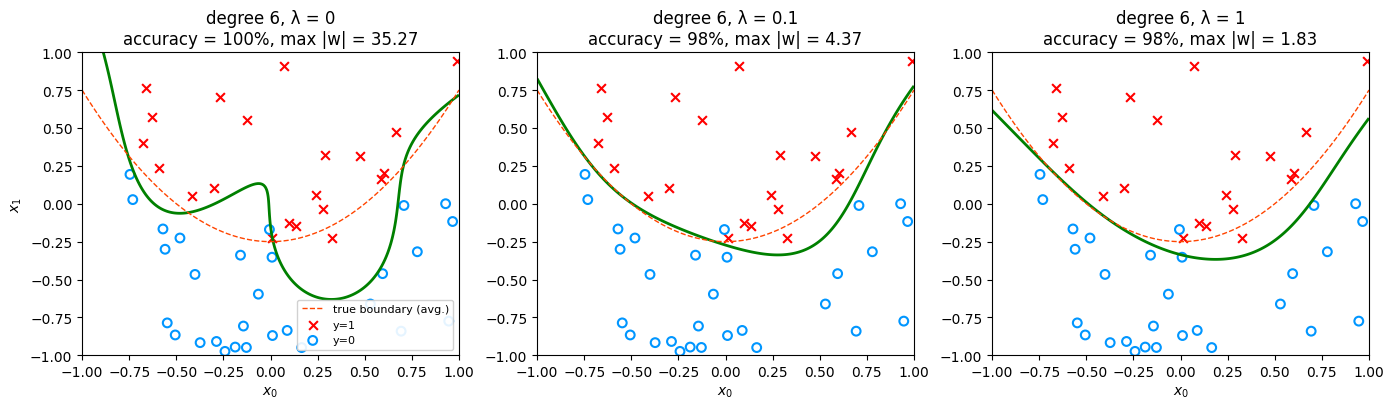

In [35]:
fig, ax = plt.subplots(1, 3, figsize=(14, 4.2))
for a, lam in zip(ax, [0, 0.1, 1]):
    w, b, mu, sig = train_logistic_poly(X_cls, y_cls, 6, lambda_=lam)
    Xn = (map_feature(X_cls[:, 0], X_cls[:, 1], 6) - mu) / sig
    acc = np.mean((sigmoid(Xn @ w + b) >= 0.5) == y_cls)
    plot_boundary(a, w, b, mu, sig, 6)
    a.plot(xi, xi ** 2 - 0.25, '--', c='orangered', lw=1, label="true boundary (avg.)")
    plot_data(X_cls, y_cls, a)
    a.set_title(f"degree 6, λ = {lam}\naccuracy = {acc:.0%}, max |w| = {np.abs(w).max():.2f}")
    a.set_xlim(-1, 1); a.set_ylim(-1, 1); a.set_xlabel("$x_0$")
ax[0].set_ylabel("$x_1$"); ax[0].legend(loc='lower right', fontsize=8, framealpha=0.9)
plt.tight_layout(); plt.show()

**Observation.** Same 27 features in all three plots. As $\lambda$ grows, the weights shrink and the boundary becomes a smooth curve close to the true boundary, even though we never removed a feature.

### 5.4 Connection to scikit-learn
In the last notebook, sklearn's `LogisticRegression` gave smaller weights than our own model. That is because it uses L2 regularization by default. Its parameter `C` is the **inverse** of $\lambda$: `C = 1/λ` (the course lab uses exactly this).

In [36]:
from sklearn.linear_model import LogisticRegression

Xm6 = map_feature(X_cls[:, 0], X_cls[:, 1], 6)
Xm6_n, mu_s, sig_s = zscore_normalize_features(Xm6)
w_ours, b_ours, _, _ = train_logistic_poly(X_cls, y_cls, 6, lambda_=1)
sk = LogisticRegression(C=1 / 1, max_iter=10000).fit(Xm6_n, y_cls)          # lambda = 1

print("our GD  (λ = 1), first 5 w:", w_ours[:5], " b:", round(b_ours, 4))
print("sklearn (C = 1), first 5 w:", sk.coef_[0][:5], " b:", round(sk.intercept_[0], 4))
print("max difference in w:", np.abs(w_ours - sk.coef_[0]).max())

our GD  (λ = 1), first 5 w: [ 0.5715  1.8279 -0.6329 -0.3387 -0.3913]  b: -1.3797
sklearn (C = 1), first 5 w: [ 0.5711  1.8272 -0.6343 -0.3399 -0.3927]  b: -1.3804
max difference in w: 0.0018969199323877195


**Observation.** Our regularized gradient descent and sklearn find (almost) the same parameters, so `LogisticRegression()` with the default `C=1.0` is regularized logistic regression with $\lambda = 1$.

## 6. Key takeaways

**Key takeaways:**
- **Underfitting = high bias:** the model is too simple to fit even the training set. **Overfitting = high variance:** it fits the training set (and its noise) too well and fails to generalize.
- A training cost of 0 is not the goal. The goal is **generalization**: good predictions on new examples.
- Fixes for overfitting: **(1)** more training data, **(2)** fewer features (feature selection), **(3) regularization**.
- Regularized cost = usual cost $+ \frac{\lambda}{2m}\sum_j w_j^2$. $b$ is not regularized.
- $\lambda = 0$ → overfit; $\lambda$ very large → $f(x) \approx b$, underfit; choose something in between.
- Gradient: add $\frac{\lambda}{m}w_j$ to $\frac{\partial J}{\partial w_j}$. Each step multiplies $w_j$ by $(1 - \alpha\lambda/m)$, slightly less than 1.
- The same change works for **linear and logistic** regression; only $f$ differs.
- scikit-learn's `LogisticRegression(C=...)` uses `C = 1/λ`.